PREPARACIÓN DEL ENTORNO Y LIBRERÍAS

In [7]:
!pip install quimb

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
!pip install tensorcircuit
!pip install qibo

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
!pip install numpy==1.26.4

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
      --------------------------------------- 0.3/15.8 MB ? eta -:--:--
     -- ------------------------------------- 1.0/15.8 MB 3.7 MB/s eta 0:00:04
     ---- ----------------------------------- 1.8/15.8 MB 3.6 MB/s eta 0:00:04
     ------- -------------------------------- 2.9/15.8 MB 4.1 MB/s eta 0:00:04
     ---------- ----------------------------- 4.2/15.8 MB 4.5 MB/s eta 0:00:03
     --------------- ------------------------ 6.0/15.8 MB 5.2 MB/s eta 0:00:02
     ------------------- -------------------- 7.6/15.8 MB 5.7 MB/s eta 0:00:02
     ------------------------ --------------- 9.7/15.8 MB 6.3 MB/s eta 0:00:01
     ----------------------------- ---------- 11.5/15.8 MB 6.6 MB/s eta 0:00:01
     ------------------------------------- -- 14.7/15.8 MB 7.5 MB/s eta 0:00:01
     ---------------------------------------- 15.8/15.8 MB 7.6 MB


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> numpy


Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Pr

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.12.0.1 requires numpy>=2.2, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.12.0.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.3.0; python_version >= "3.14", but you have numpy 1.26.4 which is incompatible.
qibo 0.3.7 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
scipy 1.18.1 requires numpy<2.8,>=2.0.0, but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: p

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

import tensorcircuit as tc
import tensorflow as tf

from qibo.hamiltonians import TFIM

TensorCircuit internamente usa tensor networks

**Resolver el modelo de Ising cuántico (TFIM) usando: VQE (Variational Quantum Eigensolver), buscando: los parámetros θ que minimizan la energía**

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import quimb as q
import quimb.tensor as qtn

import tensorcircuit as tc
import tensorflow as tf

tc.set_backend("tensorflow")
tc.set_dtype("complex64")

zz = np.kron(tc.gates._z_matrix, tc.gates._z_matrix)
print(zz)

[[ 1.  0.  0.  0.]
 [ 0. -1.  0. -0.]
 [ 0.  0. -1. -0.]
 [ 0. -0. -0.  1.]]


In [3]:
def exact_energy_tf(L, j=1.0, h=1):
    H = qtn.MPO_ham_ising(L, j=j, bx=h).to_dense()
    eigs = np.linalg.eigvalsh(H)
    return np.min(eigs)

In [4]:
def dmrg_energy(L, j=1.0, bx=0.5, bond_dims=[32,64,128,256]):
    H = qtn.MPO_ham_ising(L, j=j, bx=bx)

    dmrg = qtn.DMRG2(
        H,
        bond_dims=bond_dims
    )

    dmrg.solve(verbosity=0, tol=1e-6)

    return dmrg.energy

In [5]:
def vqe_energy(param, L, nlayers, j=1.0, h=1.0):

    zz = np.kron(tc.gates._z_matrix, tc.gates._z_matrix)

    c = tc.Circuit(L)

    param = tc.backend.cast(param, tc.dtypestr)

    for i in range(L):
        c.H(i)

    for l in range(nlayers):
        for i in range(L - 1):
            c.exp1(i, i + 1, unitary=zz, theta=param[2*l, i])

        for i in range(L):
            c.rx(i, theta=param[2*l + 1, i])


    e = 0.0
    for i in range(L):
        # Cambiamos h por h/2 para coincidir con espín-1/2
        e += -(h / 2.0) * c.expectation((tc.gates.x(), [i]))

    for i in range(L - 1):
        # Cambiamos j por j/4 para coincidir con espín-1/4
        e += -(j / 4.0) * c.expectation(
            (tc.gates.z(), [i]),
            (tc.gates.z(), [i + 1])
        )

    return tc.backend.real(e)


def train_vqe(L, nlayers=2, steps=300):

    param = tf.Variable(
        tf.random.normal([2*nlayers, L], stddev=0.1)
    )

    opt = tf.keras.optimizers.Adam(0.01)

    for i in range(steps):

        with tf.GradientTape() as tape:
            e = vqe_energy(param, L, nlayers)

        grad = tape.gradient(e, param)
        opt.apply_gradients([(grad, param)])

        if i % 100 == 0:
            print(f"VQE step {i}: energy = {e.numpy():.6f}")

    return float(e.numpy())

In [6]:
import time

def experiment():

    L_list = [4, 6,8,10,12]

    vqe_E = []
    dmrg_E = []
    exact_E = []

    times_vqe = []
    times_dmrg = []
    times_exact=[]
    nlayers = 2

    for L in L_list:

        print("L =", L)

        # -------- EXACTO --------

        if L <= 10:
            E_exact = exact_energy_tf(L)
        else:
            E_exact = np.nan

        # -------- DMRG --------
        start = time.time()

        E_dmrg = dmrg_energy(L)

        t_dmrg = time.time() - start

        # -------- VQE --------
        start = time.time()

        E_vqe = train_vqe(L, nlayers)

        t_vqe = time.time() - start



        exact_E.append(E_exact)
        dmrg_E.append(E_dmrg)
        vqe_E.append(E_vqe)

        times_dmrg.append(t_dmrg)
        times_vqe.append(t_vqe)

    return (
        L_list,
        vqe_E,
        dmrg_E,
        exact_E,
        times_vqe,
        times_dmrg,

    )

In [7]:
L_list, vqe_E, dmrg_E, exact_E, times_vqe, times_dmrg= experiment()

L = 4
VQE step 0: energy = -1.881246
VQE step 100: energy = -2.089430
VQE step 200: energy = -2.090306
L = 6
VQE step 0: energy = -2.754744
VQE step 100: energy = -3.143898
VQE step 200: energy = -3.149466
L = 8
VQE step 0: energy = -3.695408
VQE step 100: energy = -4.205794
VQE step 200: energy = -4.208621
L = 10
VQE step 0: energy = -4.720863
VQE step 100: energy = -5.257504
VQE step 200: energy = -5.267997
L = 12
VQE step 0: energy = -5.649535
VQE step 100: energy = -6.322670
VQE step 200: energy = -6.327478


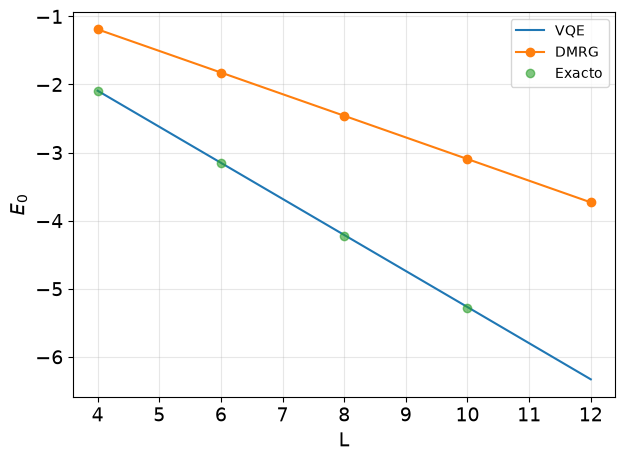

In [8]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7,5))

plt.plot(L_list, vqe_E, '-', label="VQE")
plt.plot(L_list, dmrg_E, 'o-', label="DMRG")
plt.plot(L_list, exact_E, 'o', alpha=0.6,label="Exacto")

plt.xlabel("L",fontsize=14)
plt.ylabel(r"$E_0$",fontsize=14)

plt.grid(alpha=0.3)
plt.legend()
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()

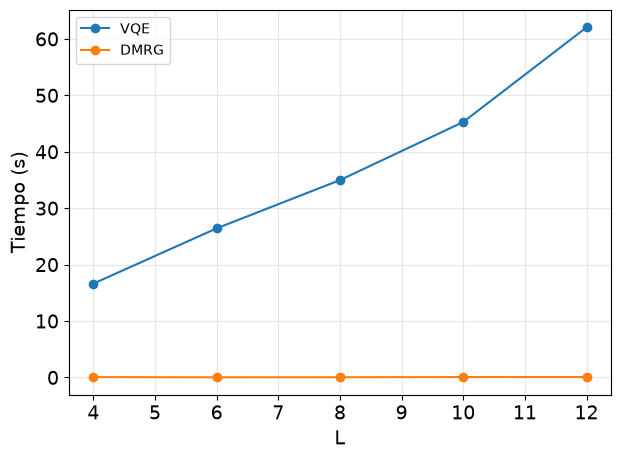

In [9]:
plt.figure(figsize=(7,5))

plt.plot(L_list, times_vqe, 'o-', label='VQE')
plt.plot(L_list, times_dmrg, 'o-', label='DMRG')

plt.xlabel('L',fontsize=14)
plt.ylabel('Tiempo (s)',fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()